In [92]:
import json
import pandas as pd
import matplotlib.pyplot as plt


In [104]:
train_data = "../data/raw/otto-recsys-train.jsonl"

partial_data = []
with open(train_data, "r") as file:
    for i, line in enumerate(file):
        if i >= 15000:
            break
        partial_data.append(json.loads(line)) 

In [105]:
for i in range(1):
    print(partial_data[i])

{'session': 0, 'events': [{'aid': 1517085, 'ts': 1659304800025, 'type': 'clicks'}, {'aid': 1563459, 'ts': 1659304904511, 'type': 'clicks'}, {'aid': 1309446, 'ts': 1659367439426, 'type': 'clicks'}, {'aid': 16246, 'ts': 1659367719997, 'type': 'clicks'}, {'aid': 1781822, 'ts': 1659367871344, 'type': 'clicks'}, {'aid': 1152674, 'ts': 1659367885796, 'type': 'clicks'}, {'aid': 1649869, 'ts': 1659369893840, 'type': 'carts'}, {'aid': 461689, 'ts': 1659369898050, 'type': 'carts'}, {'aid': 305831, 'ts': 1659370027105, 'type': 'orders'}, {'aid': 461689, 'ts': 1659370027105, 'type': 'orders'}, {'aid': 362233, 'ts': 1659370064916, 'type': 'clicks'}, {'aid': 1649869, 'ts': 1659370067686, 'type': 'clicks'}, {'aid': 1649869, 'ts': 1659371003682, 'type': 'clicks'}, {'aid': 984597, 'ts': 1659371033243, 'type': 'clicks'}, {'aid': 1649869, 'ts': 1659371042297, 'type': 'clicks'}, {'aid': 803544, 'ts': 1659371044075, 'type': 'clicks'}, {'aid': 1110941, 'ts': 1659371104329, 'type': 'clicks'}, {'aid': 1190046

In [114]:
def get_stats(data):
    total_sessions = len(data)

    total_events = 0
    total_clicks = 0
    total_orders = 0
    total_carts = 0

    session_stats = {}
    
    for session in data:
        events = session['events']
        event_count = len(events)
        clicks = sum(1 for event in events if event['type'] == 'clicks')
        orders = sum(1 for event in events if event['type'] == 'orders')
        carts = sum(1 for event in events if event['type'] == 'carts')

        total_events += event_count
        total_clicks += clicks
        total_orders += orders
        total_carts += carts

        if events:
            min_ts = min(event['ts'] for event in events)
            max_ts = max(event['ts'] for event in events)
            session_length = round((max_ts - min_ts) / 1000 / 60, 3)  # milliseconds to minutes
            weeks = round(session_length / 60 / 24 / 7, 3)  # minutes to weeks

            unique_products = len({event['aid'] for event in events})
            revisits = event_count - unique_products

            click_frequency = round(clicks / event_count if event_count > 0 else 0, 3)
            order_frequency = round(orders / event_count if event_count > 0 else 0, 3)
            cart_frequency = round(carts / event_count if event_count > 0 else 0, 3)
            
        else:
            session_length = 0

        session_stats[session['session']] = {
            'events': event_count,
            'clicks': clicks,
            'click_frequency': click_frequency,
            'orders': orders,
            'order_frequency': order_frequency,
            'carts': carts,
            'cart_frequency': cart_frequency,
            'unique_products': unique_products,
            'revisits': revisits,
            'session_length': session_length,
            'weeks': weeks
        }

    return {
        'total_sessions': total_sessions,
        'total_events': total_events,
        'total_clicks': total_clicks,
        'total_orders': total_orders,
        'total_carts': total_carts,
        'session_stats': session_stats
    }

stats = get_stats(partial_data)

In [108]:
print("total sessions: ", stats['total_sessions'])
print("total_events: ", stats['total_events'])
print("total_clicks: ", stats['total_clicks'])
print("total_orders: ", stats['total_orders'])
print("total_carts: ", stats['total_carts'])
# print(stats['session_stats'])

total sessions:  15000
total_events:  887239
total_clicks:  807697
total_orders:  16698
total_carts:  62844


In [109]:
def new_data(data):
    stats = get_stats(data)
    session_stats = stats['session_stats']

    df = pd.DataFrame.from_dict(session_stats, orient='index')
    df.index.name = 'session_id'
    df = df.reset_index()

    return df

df = new_data(partial_data)
df


,session_id,events,clicks,click_frequency,orders,order_frequency,carts,cart_frequency,unique_events,revisits,session_length,weeks
0,0,276,255,0.924,4,0.014,17,0.062,183,93,39669.728,3.935
1,1,32,24,0.750,0,0.000,8,0.250,22,10,40167.583,3.985
2,2,33,32,0.970,0,0.000,1,0.030,29,4,40156.927,3.984
3,3,226,200,0.885,5,0.022,21,0.093,140,86,30081.111,2.984
4,4,19,15,0.789,1,0.053,3,0.158,12,7,38031.353,3.773
...,...,...,...,...,...,...,...,...,...,...,...,...
14995,14995,2,2,1.000,0,0.000,0,0.000,1,1,0.388,0.000
14996,14996,8,8,1.000,0,0.000,0,0.000,7,1,50.159,0.005
14997,14997,37,33,0.892,2,0.054,2,0.054,17,20,36481.828,3.619
14998,14998,16,10,0.625,2,0.125,4,0.250,5,11,1318.944,0.131


In [112]:
print(max(df['weeks']))
print(min(df['weeks']))

4.0
0.0


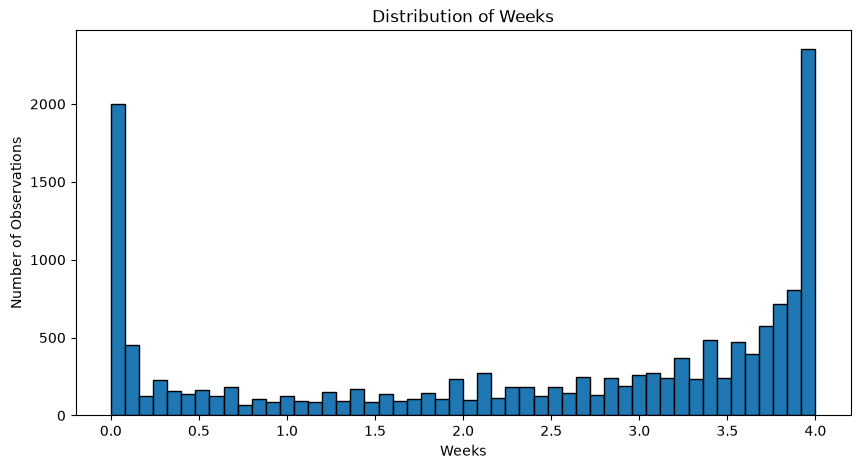

In [111]:
plt.figure(figsize=(10, 5))

plt.hist(df['weeks'], bins=50, edgecolor='black')

plt.xlabel('Weeks')
plt.ylabel('Number of Observations')
plt.title('Distribution of Weeks')

plt.show()